##### To check the count of images are in each defect class

In [1]:
from pathlib import Path 
root = Path(r"C:\Tasks\Steel Surface Defect Inspection System\data\NEU-DET")
for split in ["train", "validation"]:
    print(split)
    for folder in sorted((root/split/"images").iterdir()):
        print(" ", folder.name, len(list(folder.glob("*.jpg"))))

train
  crazing 240
  inclusion 240
  patches 240
  pitted_surface 240
  rolled-in_scale 240
  scratches 240
validation
  crazing 60
  inclusion 60
  patches 60
  pitted_surface 60
  rolled-in_scale 60
  scratches 60


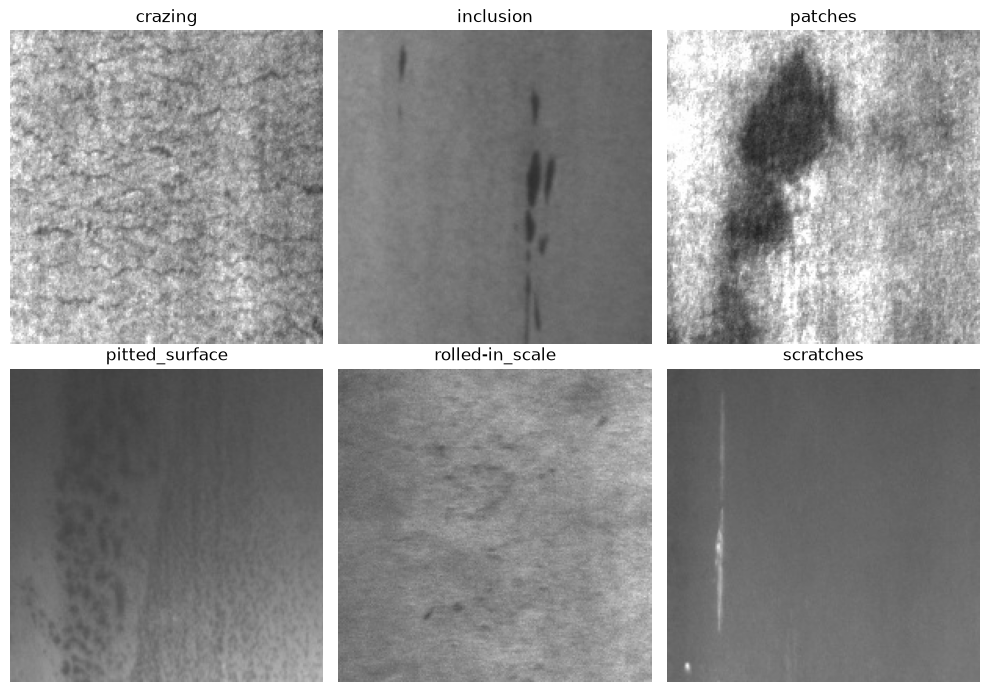

In [2]:
import matplotlib.pyplot as plt
import cv2

classes = ["crazing", "inclusion", "patches", "pitted_surface", "rolled-in_scale", "scratches"]
fig, axes = plt.subplots(2, 3, figsize=(10, 7))

for ax, c in zip(axes.ravel(), classes):
    folder = root/"train"/"images"/c
    img_path = next(folder.glob("*.jpg"))
    img = cv2.imread(str(img_path))
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(c)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [3]:
print(img.shape)

(200, 200, 3)


In [4]:
import sys 
sys.path.append(r"C:\Tasks\Steel Surface Defect Inspection System\src")
from dataset import SteelDefectDataset

classes = ["crazing", "inclusion", "patches", "pitted_surface", "rolled-in_scale", "scratches"]
train_ds = SteelDefectDataset(root,"train", classes)

print(len(train_ds))

img, label = train_ds[0]
print(img.shape, label)

1440
(200, 200, 3) 0


In [ ]:
from transform import train_transform

train_ds = SteelDefectDataset(root, "train", classes, transform= train_transform)
img, label = train_ds[0]